# 06 · Learning curve: would more wafers help?
**Burn In Only What Matters** · ECE 8803-AI4 · Fall 2026

Each model is trained on a subset of the training lots, with leave-one-lot-out on Lots 1–4 as in
notebooks 02 and 04. The subset sizes are 2, 4, 7 or 10 wafers per lot, giving 6, 12, 21 or 30
training wafers per fold. Each model is scored out-of-fold on the full held-out lot.

If a model's recall is still rising at 30 wafers, more data (the full 200-wafer lots) should help it.
If it has flattened, it is limited by the information in the data, not by the amount of data.

* The U-Net's epoch count is scaled so that every size gets roughly the same number of gradient steps.
  Early stopping still picks the best epoch on the held-out lot.
* Small subsets are repeated with different random wafer draws.
* Only the no-pre-training U-Net is run; notebook 04 showed pre-training gives no measurable gain.
* Results are cached in `results/sim_dev/learning_curve.csv`; set `RERUN = True` to recompute (~15 min on GPU).
* Lot 5 is not used.

## 0 · Setup

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
COLAB_ROOT = "/content/drive/MyDrive/BurnIn_Project"
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path(COLAB_ROOT)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "burnin").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from burnin import Paths
from burnin.config import TRAIN_LOTS
from burnin.data import load_visible, attach_hidden
from burnin.metrics import screening_curve
from burnin.cv import UNET_DEFAULTS, fit_baselines, score_baselines, unet_inputs
from burnin.train import train_unet, predict_unet

SIM = os.environ.get("BURNIN_SIM", "sim_dev")
P = Paths(ROOT, sim=SIM)
print("dataset:", P.sim_dir)
ws = attach_hidden(load_visible(P.visible), P.hidden).lots(TRAIN_LOTS)
PER_LOT = [2, 4, 7, 10]
REPEATS = {2: 2, 4: 2, 7: 1, 10: 1}
MAX_EPOCHS = 150
RERUN = False
BASE_EPOCHS = 60

dataset: C:\Users\nsaba\OneDrive - Analog Devices, Inc\Documents\Chipagents\8803\Project\cache\sim_dev


## 1 · Run

In [2]:
def subsample(train_ws, k, rng):
    keep = np.zeros(len(train_ws), bool)
    for lot in np.unique(train_ws.lot):
        idx = np.flatnonzero(train_ws.lot == lot)
        keep[rng.choice(idx, k, replace=False)] = True
    return train_ws.subset(keep)

cfg = {k: v for k, v in UNET_DEFAULTS.items() if k not in ("derived", "epochs", "eval_every")}
cfg["eval_every"] = 5
rows = []
t0 = time.time()
CACHE = P.results / "learning_curve.csv"
for k in (PER_LOT if RERUN or not CACHE.exists() else []):
    epochs = min(MAX_EPOCHS, int(round(BASE_EPOCHS * 10 / k)))
    for rep in range(REPEATS[k]):
        rng = np.random.default_rng(100 * k + rep)
        oof = {}
        for val in TRAIN_LOTS:
            vm = np.isin(ws.lot, [val])
            va = ws.subset(vm)
            tr = subsample(ws.lots([l for l in TRAIN_LOTS if l != val]), k, rng)
            b = score_baselines(fit_baselines(tr, seed=rep), va, seed=rep)
            for name in ["Feature GBM", "Hotelling T2 (PCA)", "Distance to fail"]:
                oof.setdefault(name, np.zeros(ws.fail.shape, np.float32))[vm] = b[name]
            _, (Xa, Xb) = unet_inputs(tr, [tr, va], UNET_DEFAULTS["derived"])
            for name, enc in [("U-Net (no pre-training)", None)]:
                net, _, _ = train_unet(Xa, tr.latent, tr.passing, Xb, va.latent, va.passing, encoder_state=enc,
                                       epochs=epochs, seed=rep, log=lambda s: None, **cfg)
                oof.setdefault(name, np.zeros(ws.fail.shape, np.float32))[vm] = np.where(va.passing, predict_unet(net, Xb), 0)
        for name, s in oof.items():
            c = screening_curve(s, ws.latent, ws.passing)
            rows.append({"wafers/fold": 3 * k, "repeat": rep, "method": name,
                         "recall@10%": c.recall_at(0.10), "AP": c.average_precision(), "AUC": c.auc()})
        print(f"{3 * k:2d} wafers/fold, repeat {rep}: done ({time.time() - t0:.0f}s)", flush=True)
if rows:
    lc = pd.DataFrame(rows)
    lc.to_csv(CACHE, index=False)
else:
    lc = pd.read_csv(CACHE)
    print(f"loaded cached {CACHE.name}")

loaded cached learning_curve.csv


## 2 · Results (mean ± std over repeats)

In [3]:
summ = lc.groupby(["method", "wafers/fold"])[["recall@10%", "AP"]].agg(["mean", "std"]).round(3)
summ

recall@10%            AP       
                                          mean    std   mean    std
method                  wafers/fold                                
Distance to fail        6                0.345  0.000  0.029  0.000
                        12               0.345  0.000  0.029  0.000
                        21               0.345    NaN  0.029    NaN
                        30               0.345    NaN  0.029    NaN
Feature GBM             6                0.576  0.000  0.215  0.000
                        12               0.587  0.001  0.225  0.001
                        21               0.594    NaN  0.230    NaN
                        30               0.599    NaN  0.233    NaN
Hotelling T2 (PCA)      6                0.478  0.001  0.191  0.000
                        12               0.478  0.000  0.191  0.000
                        21               0.477    NaN  0.191    NaN
                        30               0.477    NaN  0.191    NaN
U-Net (no pre-training) 6                0.481  0.000  0.079  0.011
                        12               0.546  0.008  0.126  0.002
                        21               0.568    NaN  0.168    NaN
                        30               0.572    NaN  0.175    NaN

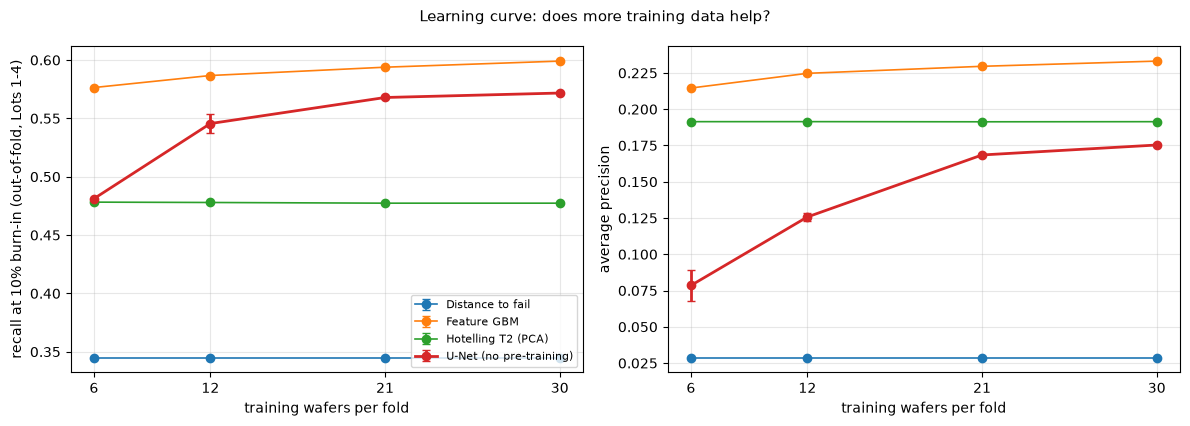

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for name, g in lc.groupby("method"):
    m = g.groupby("wafers/fold")[["recall@10%", "AP"]].agg(["mean", "std"])
    x = m.index.values
    for a, col in zip(ax, ["recall@10%", "AP"]):
        a.errorbar(x, m[(col, "mean")], yerr=m[(col, "std")].fillna(0), marker="o", capsize=3,
                   lw=2 if "U-Net" in name else 1.2, label=name)
ax[0].set_ylabel("recall at 10% burn-in (out-of-fold, Lots 1-4)")
ax[1].set_ylabel("average precision")
for a in ax:
    a.set_xlabel("training wafers per fold")
    a.set_xticks([6, 12, 21, 30])
    a.grid(alpha=0.3)
ax[0].legend(fontsize=8)
fig.suptitle("Learning curve: does more training data help?", fontsize=11)
plt.tight_layout()
plt.savefig(P.results / "figures" / "learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## 3 · Slope over the last doubling
Gain in recall@10% per doubling of training data, from a log-linear fit on the 12, 21 and 30 wafer
points. A clearly positive slope means the model is still data-limited.

In [5]:
slope = {}
for name, g in lc.groupby("method"):
    m = g.groupby("wafers/fold")["recall@10%"].mean()
    m = m[m.index >= 12]
    slope[name] = np.polyfit(np.log2(m.index.values), m.values, 1)[0]
pd.Series(slope, name="recall@10% gain per doubling of wafers").round(3).sort_values(ascending=False)

U-Net (no pre-training)    0.020
Feature GBM                0.009
Distance to fail          -0.000
Hotelling T2 (PCA)        -0.000
Name: recall@10% gain per doubling of wafers, dtype: float64